<a href="https://colab.research.google.com/github/angelpavu/A05-pca/blob/main/notebook_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Angel Pavu

**Date:** 10/19/2026

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]
unique tokens: 48691 | total tokens: 276949


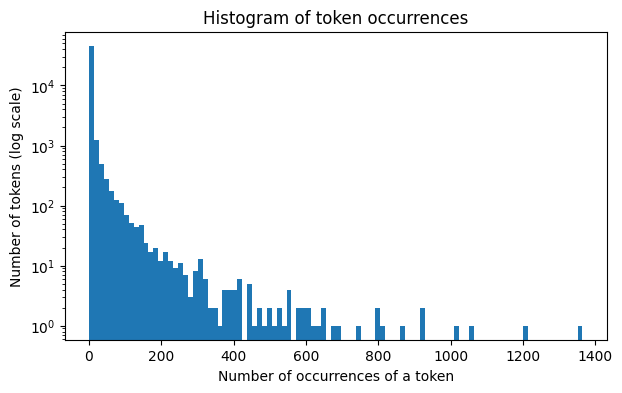

In [8]:
# Your Phase 1 solution to the problem goes here.

# Question 1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = np.array([c for _, c in token_freq])

print(token_freq[:20])
print("unique tokens:", len(counts), "| total tokens:", counts.sum())

# Histogram of occurrences (how many tokens occur n times)
plt.figure(figsize=(7, 4))
plt.hist(counts, bins=100)
plt.yscale('log')
plt.xlabel('Number of occurrences of a token')
plt.ylabel('Number of tokens (log scale)')
plt.title('Histogram of token occurrences')
plt.show()


Question 1

The histogram is right-skewed, so most of the tokens have a lower number of which they occur. There is a much fewer number of tokens that have a greater occurence rate, so that is why the bar is so tall at the lower numbers and then gets shorter. On a regular y-axis the bars for the rare-token bins would dwarf everything else, making the tail invisible. The log scale keeps both the huge low-count bars and the tiny high-count bars visible, so you can see the full shape of the distribution.

In [10]:
# Question 2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet('/content/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("train shape:", X_train.shape, "test shape:", X_test.shape)

reg = LinearRegression().fit(X_train, y_train)
print("Train R2:", r2_score(y_train, reg.predict(X_train)))
print("Test  R2:", r2_score(y_test, reg.predict(X_test)))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(15))

train shape: (14907, 2711) test shape: (3727, 2711)
Train R2: 0.7670143724934355
Test  R2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64


Question 2

I split the data 80/20 into 14,907 training emails and 3,727 test emails, each with 2,711 token features, and regressed Email Type (1 = scam, 0 = not) on the one-hot-encoded tokens. The model has a training R² of about 0.767 and a test R² of about 0.666. The drop from train to test suggests some overfitting which makes sense with 2,711 features, but the model still generalizes well.

The words with the largest absolute coefficients are intervention (-1.26), localized (0.82), thermal (0.75), crawler (0.70), background-image: (-0.62), helvetica, (0.60), aging (0.59), and form. (0.58).

Explained variance ratio: [0.01113088 0.00861212]


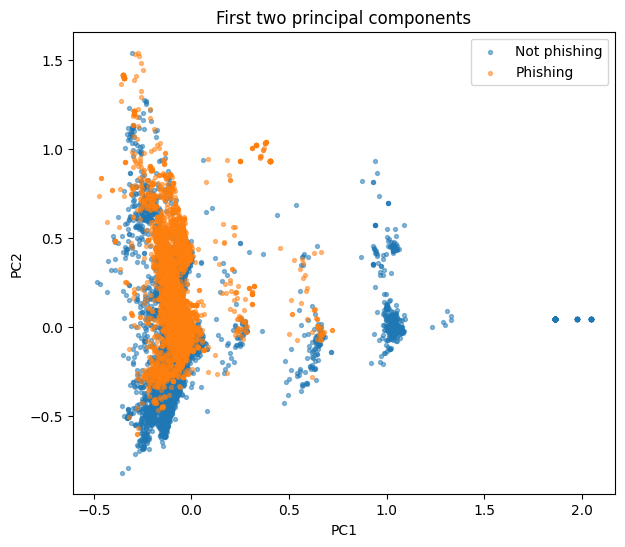

In [11]:
# Question 3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)
print("Explained variance ratio:", pca2.explained_variance_ratio_)

plt.figure(figsize=(7, 6))
for label, name in [(0, 'Not phishing'), (1, 'Phishing')]:
    m = (y.values == label)
    plt.scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.5, label=name)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.title('First two principal components')
plt.show()

Question 3

The two components explain only about 2% of the total variance (1.1% and 0.9%), so the plot captures little of the data. Phishing emails in orange are packed into a dense and narrow band near PC1 ≈ 0, while non-phishing emails in blue are more spread out. They extend further down on PC2 and form separate clusters at higher PC1 values (around 0.5, 1.0, and 2.0) with almost no phishing. In the center the two classes overlap heavily, so two components are not enough to cleanly separate phishing from non-phishing emails.

In [12]:
# Question 4
pca = PCA(n_components=2610)
Ztr = pca.fit_transform(X_train)
Zte = pca.transform(X_test)

reg_pc = LinearRegression().fit(Ztr, y_train)
print("PC regression Train R2:", r2_score(y_train, reg_pc.predict(Ztr)))
print("PC regression Test  R2:", r2_score(y_test, reg_pc.predict(Zte)))
print("Variance explained by 2,610 PCs:", pca.explained_variance_ratio_.sum())

PC regression Train R2: 0.7662326827745849
PC regression Test  R2: 0.6683390643101164
Variance explained by 2,610 PCs: 0.9998620409568273


Question 4

Regressing y on the first 2,610 principal components gives a training R² of about 0.766 and a test R² of about 0.668. This is almost identical to the original regression on all 2,711 tokens (train 0.767, test 0.666). The 2,610 components capture about 99.99% of the total variance in X, so they keep essentially all of the information in the original features. A linear regression on principal components is just a regression on a rotated version of the data. Dropping only the 101 lowest-variance components removes almost nothing, so the fit barely changes. The train R² is slightly lower (by about 0.001) because a few directions were dropped, and the test R² is slightly higher (by about 0.002), which suggests that removing those low-variance, mostly noisy directions helps a tiny bit.

Question 5

The original data has thousands of word columns, and many of them overlap or move together (for example, words that tend to show up in the same emails). That makes a regression on the raw data unstable and prone to overfitting. Principal components combine those overlapping words into a smaller set of new variables that are uncorrelated with each other and ordered by how much information they hold. This means we can keep only the most important components and drop the weak, noisy ones, which gives us fewer variables to fit, a simpler model, and less overfitting. It can also make the regression faster. In our case we kept 2,610 of the 2,711 components, so the results barely changed, but keeping fewer would show the benefit more clearly. The tradeoff is that each component is a mix of many words, so it’s harder to interpret than a single word.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]